# Model on Customer churn prediction

In [1]:
# Importing the libraries

In [2]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [14]:
# Importing the dataset and perform EDA and Encoding

In [4]:
df = pd.read_csv('Churn_dataset.csv')
print("Initial shape:", df.shape)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

df.dropna(inplace=True)
print("Shape after dropna:", df.shape)

df.drop('customerID', axis=1, inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print("Shape before encoding:", df.shape)

df_encoded = pd.get_dummies(df, drop_first=True)
print("Final shape:", df_encoded.shape)

Initial shape: (7043, 21)
Missing TotalCharges: 11
Shape after dropna: (7032, 21)
Shape before encoding: (7032, 20)
Final shape: (7032, 31)


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
#Handle Class Imbalance (SMOTE)

In [8]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print(y_train_bal.value_counts())

Churn
0    4130
1    4130
Name: count, dtype: int64


In [17]:
# Train the model

In [9]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_bal, y_train_bal)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_bal, y_train_bal)

xgb = XGBClassifier(random_state=42, eval_metric='logloss')
xgb.fit(X_train_bal, y_train_bal)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [18]:
# Check accuracy

In [10]:
for name, model in [('Logistic Regression', log_reg), ('Random Forest', rf), ('XGBoost', xgb)]:
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    print(f"\n--- {name} ---")
    print(classification_report(y_test, preds))
    print("ROC-AUC:", roc_auc_score(y_test, probs))


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1033
           1       0.50      0.78      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.75      1407

ROC-AUC: 0.8338842269284726

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.85      0.84      0.85      1033
           1       0.58      0.60      0.59       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407

ROC-AUC: 0.8176835549849615

--- XGBoost ---
              precision    recall  f1-score   support

           0       0.85      0.84      0.84      1033
           1       0.57      0.59      0.58       374

    accuracy                           0.77      1407
   

In [19]:
# Feature importance

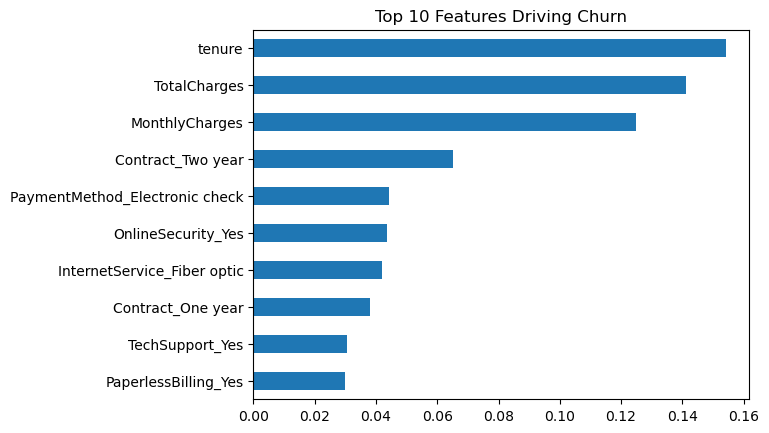

In [11]:
importances = rf.feature_importances_
feat_names = X.columns
top_features = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(10)

top_features.plot(kind='barh')
plt.title('Top 10 Features Driving Churn')
plt.gca().invert_yaxis()
plt.show()

In [20]:
# Save the model for later prediction

In [12]:
import joblib

joblib.dump(xgb, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(X.columns.tolist(), 'model_columns.pkl')

['model_columns.pkl']

In [21]:
# Make the real prediction

In [13]:
model = joblib.load('churn_model.pkl')
scaler = joblib.load('scaler.pkl')
model_columns = joblib.load('model_columns.pkl')

new_customer = pd.DataFrame({
    'gender': ['Female'], 'SeniorCitizen': [0], 'Partner': ['Yes'], 'Dependents': ['No'],
    'tenure': [2], 'PhoneService': ['Yes'], 'MultipleLines': ['No'],
    'InternetService': ['Fiber optic'], 'OnlineSecurity': ['No'], 'OnlineBackup': ['No'],
    'DeviceProtection': ['No'], 'TechSupport': ['No'], 'StreamingTV': ['Yes'],
    'StreamingMovies': ['Yes'], 'Contract': ['Month-to-month'], 'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Electronic check'], 'MonthlyCharges': [95.5], 'TotalCharges': [191.0]
})

new_encoded = pd.get_dummies(new_customer)
new_encoded = new_encoded.reindex(columns=model_columns, fill_value=0)
new_scaled = scaler.transform(new_encoded)

pred = model.predict(new_scaled)[0]
prob = model.predict_proba(new_scaled)[:, 1][0]

print("Will churn?" , "Yes" if pred == 1 else "No")
print(f"Churn probability: {prob*100:.2f}%")

Will churn? Yes
Churn probability: 87.62%
